# Tugas Praktikum 4: Association Rule

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules

pd.set_option('display.max_colwidth', 100)

### 1. Import Dataset

In [4]:
df = pd.read_excel('Online Retail.xlsx')

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print("Shape dataset:", df.shape)

df.info()

Shape dataset: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


### 2. Eksplorasi dan Pembersihan Data

In [6]:
# kolom yang relevan untuk association rule
df[['InvoiceNo', 'Description', 'Quantity']].head()

,InvoiceNo,Description,Quantity
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6
1,536365,WHITE METAL LANTERN,6
2,536365,CREAM CUPID HEARTS COAT HANGER,8
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6


In [7]:
df['InvoiceNo'] = df['InvoiceNo'].astype(str)

print("Missing values pada dataset:")
print(df.isnull().sum())

print()
print("Description kosong          :", df['Description'].isnull().sum())
print("Transaksi dibatalkan (C...)  :", df['InvoiceNo'].str.startswith('C').sum())
print("Quantity <= 0                :", (df['Quantity'] <= 0).sum())

Missing values pada dataset:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Description kosong          : 1454
Transaksi dibatalkan (C...)  : 9288
Quantity <= 0                : 10624


In [8]:
baris_sebelum = df.shape[0]
invoice_sebelum = df['InvoiceNo'].nunique()

df_clean = df.dropna(subset=['Description'])
df_clean = df_clean[~df_clean['InvoiceNo'].str.startswith('C')]
df_clean = df_clean[df_clean['Quantity'] > 0].copy()

df_clean['Description'] = df_clean['Description'].str.strip()

baris_sesudah = df_clean.shape[0]
invoice_sesudah = df_clean['InvoiceNo'].nunique()

perbandingan = pd.DataFrame({
    'Sebelum': [baris_sebelum, invoice_sebelum],
    'Sesudah': [baris_sesudah, invoice_sesudah],
}, index=['Jumlah Baris', 'Jumlah Invoice'])
perbandingan['Terhapus'] = perbandingan['Sebelum'] - perbandingan['Sesudah']

display(perbandingan)
print("Jumlah produk unik setelah pembersihan:", df_clean['Description'].nunique())

,Sebelum,Sesudah,Terhapus
Jumlah Baris,541909,530693,11216
Jumlah Invoice,25900,20136,5764


Jumlah produk unik setelah pembersihan: 4065


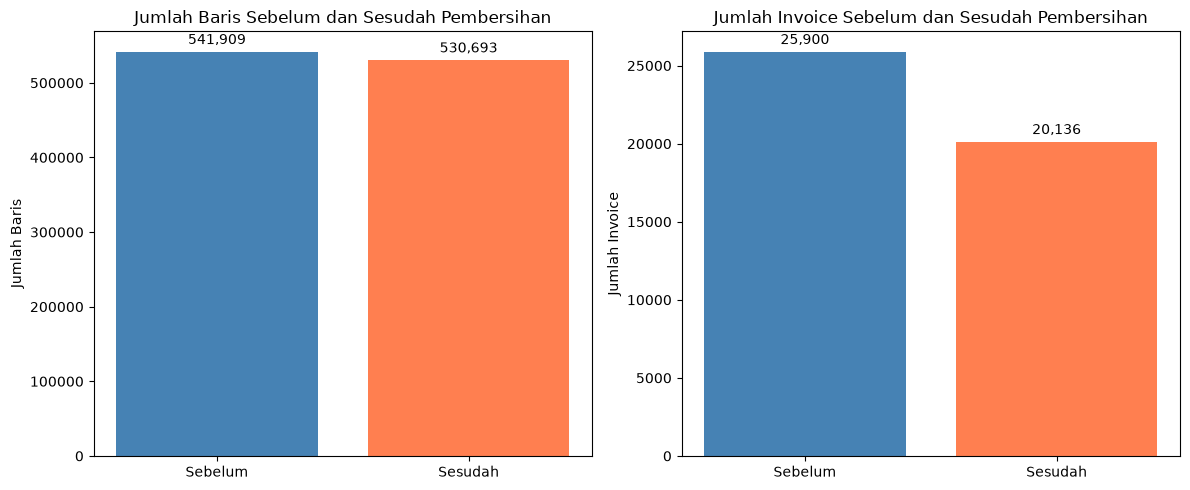

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, kolom in zip(axes, perbandingan.index):
    bars = ax.bar(['Sebelum', 'Sesudah'], perbandingan.loc[kolom, ['Sebelum', 'Sesudah']],
                  color=['steelblue', 'coral'])
    ax.bar_label(bars, fmt='{:,.0f}', padding=3)
    ax.set_title(f'{kolom} Sebelum dan Sesudah Pembersihan')
    ax.set_ylabel(kolom)

plt.tight_layout()
plt.show()

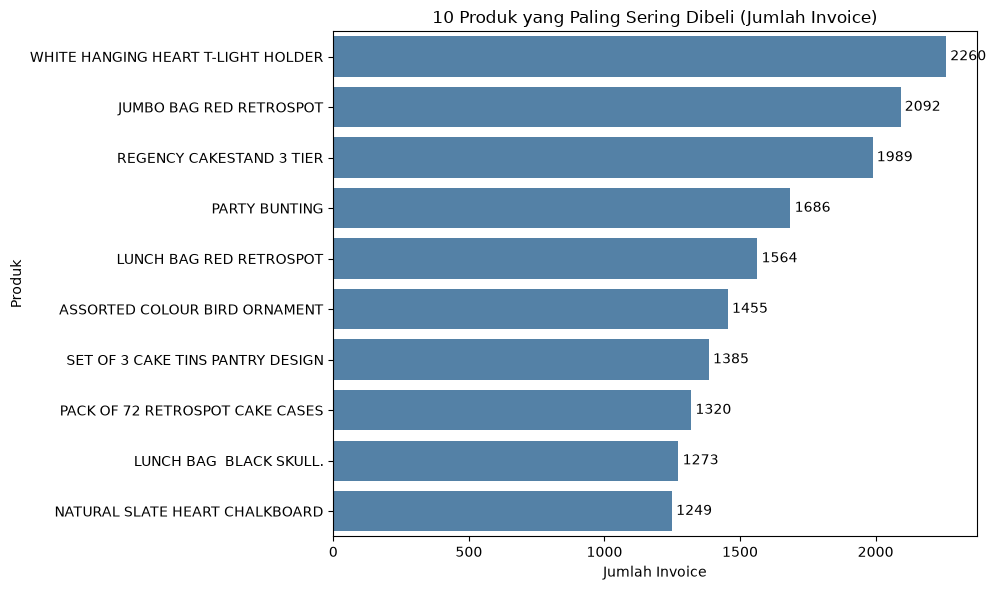

In [10]:
top_produk = df_clean.groupby('Description')['InvoiceNo'].nunique().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=top_produk.values, y=top_produk.index, color='steelblue')
ax.bar_label(ax.containers[0], padding=3)
plt.title('10 Produk yang Paling Sering Dibeli (Jumlah Invoice)')
plt.xlabel('Jumlah Invoice')
plt.ylabel('Produk')
plt.tight_layout()
plt.show()

### 3. Persiapan Data untuk Association Rule

In [11]:
transaksi = df_clean.groupby('InvoiceNo')['Description'].apply(lambda x: list(set(x)))

print("Jumlah transaksi:", len(transaksi))
transaksi.head()

Jumlah transaksi: 20136


InvoiceNo
536365    [CREAM CUPID HEARTS COAT HANGER, WHITE HANGING HEART T-LIGHT HOLDER, SET 7 BABUSHKA NESTING BOXE...
536366                                                    [HAND WARMER UNION JACK, HAND WARMER RED POLKA DOT]
536367    [POPPY'S PLAYHOUSE BEDROOM, FELTCRAFT PRINCESS CHARLOTTE DOLL, POPPY'S PLAYHOUSE KITCHEN, ASSORT...
536368    [JAM MAKING SET WITH JARS, YELLOW COAT RACK PARIS FASHION, RED COAT RACK PARIS FASHION, BLUE COA...
536369                                                                             [BATH BUILDING BLOCK WORD]
Name: Description, dtype: object

In [12]:
te = TransactionEncoder()
te_array = te.fit_transform(transaksi.tolist())
basket = pd.DataFrame(te_array, columns=te.columns_)

print("Shape basket (transaksi x produk):", basket.shape)
basket.head()

Shape basket (transaksi x produk): (20136, 4065)


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,...,returned,taig adjust,test,to push order througha s stock was,website fixed,wrongly coded 20713,wrongly coded 23343,wrongly marked,wrongly marked 23343,wrongly sold (22719) barcode
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### 4. Penerapan Algoritma FP-Growth

In [13]:
# titik awal: min support 0.01, min confidence 0.5
frequent_itemsets = fpgrowth(basket, min_support=0.01, use_colnames=True)
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.5)

print("Jumlah frequent itemset:", len(frequent_itemsets))
print("Jumlah aturan asosiasi :", len(rules))

Jumlah frequent itemset: 1853
Jumlah aturan asosiasi : 841


In [14]:
# coba beberapa nilai min support untuk melihat pengaruhnya terhadap jumlah aturan
hasil = []
for s in [0.01, 0.015, 0.02, 0.025, 0.03]:
    fi = fpgrowth(basket, min_support=s, use_colnames=True)
    r = association_rules(fi, metric='confidence', min_threshold=0.5)
    hasil.append({'min_support': s, 'jumlah_itemset': len(fi), 'jumlah_aturan': len(r)})

hasil_support = pd.DataFrame(hasil)
display(hasil_support)

,min_support,jumlah_itemset,jumlah_aturan
0,0.010,1853,841
1,0.015,695,177
2,0.020,376,61
3,0.025,222,37
4,0.030,136,11


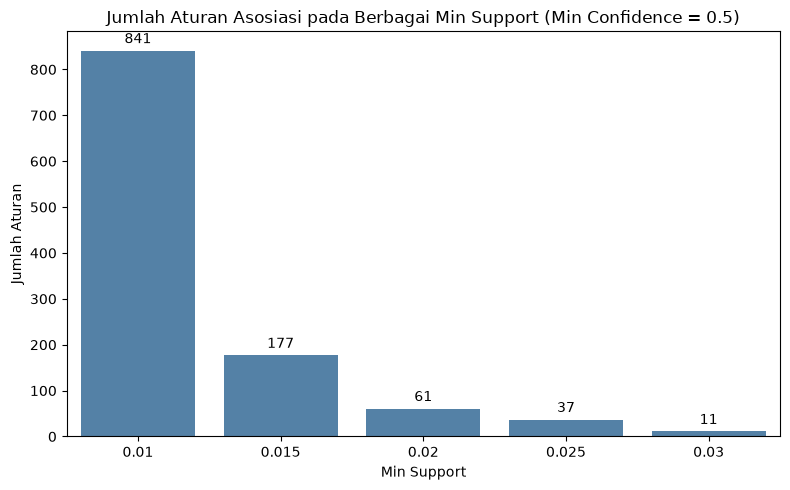

In [15]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=hasil_support, x='min_support', y='jumlah_aturan', color='steelblue')
ax.bar_label(ax.containers[0], padding=3)
plt.title('Jumlah Aturan Asosiasi pada Berbagai Min Support (Min Confidence = 0.5)')
plt.xlabel('Min Support')
plt.ylabel('Jumlah Aturan')
plt.tight_layout()
plt.show()

In [16]:
# min support disesuaikan menjadi 0.02 karena 0.01 menghasilkan terlalu banyak aturan
min_support = 0.02
min_confidence = 0.5

frequent_itemsets = fpgrowth(basket, min_support=min_support, use_colnames=True)
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=min_confidence)

print("Jumlah frequent itemset:", len(frequent_itemsets))
print("Jumlah aturan asosiasi :", len(rules))

Jumlah frequent itemset: 376
Jumlah aturan asosiasi : 61


In [17]:
frequent_itemsets.sort_values('support', ascending=False).head(10)

,support,itemsets
0,0.112237,frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
67,0.103894,frozenset({JUMBO BAG RED RETROSPOT})
163,0.098778,frozenset({REGENCY CAKESTAND 3 TIER})
233,0.083731,frozenset({PARTY BUNTING})
30,0.077672,frozenset({LUNCH BAG RED RETROSPOT})
4,0.072259,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
244,0.068782,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN})
31,0.065554,frozenset({PACK OF 72 RETROSPOT CAKE CASES})
108,0.063220,frozenset({LUNCH BAG BLACK SKULL.})
57,0.062028,frozenset({NATURAL SLATE HEART CHALKBOARD})


### 5. Evaluasi Aturan Asosiasi

In [18]:
rules['antecedents'] = rules['antecedents'].apply(lambda x: ', '.join(sorted(x)))
rules['consequents'] = rules['consequents'].apply(lambda x: ', '.join(sorted(x)))

rules_tampil = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
rules_tampil = rules_tampil.sort_values('lift', ascending=False).reset_index(drop=True)

display(rules_tampil.round(4))

,antecedents,consequents,support,confidence,lift
0,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",0.0269,0.7076,18.5516
1,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",PINK REGENCY TEACUP AND SAUCER,0.0269,0.7057,18.5516
2,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",0.0269,0.5340,17.9506
3,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",GREEN REGENCY TEACUP AND SAUCER,0.0269,0.9048,17.9506
4,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0314,0.8264,16.3939
...,...,...,...,...,...
56,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED RETROSPOT,0.0338,0.5787,5.5704
57,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",REGENCY CAKESTAND 3 TIER,0.0203,0.5313,5.3782
58,JUMBO BAG APPLES,JUMBO BAG RED RETROSPOT,0.0271,0.5583,5.3736
59,RECYCLING BAG RETROSPOT,JUMBO BAG RED RETROSPOT,0.0206,0.5548,5.3402


In [19]:
rules_tampil[['support', 'confidence', 'lift']].describe().round(4)

,support,confidence,lift
count,61.0000,61.0000,61.0000
mean,0.0261,0.6238,10.9929
std,0.0049,0.0976,4.2088
min,0.0202,0.5006,5.0768
25%,0.0223,0.5518,6.5196
50%,0.0261,0.6003,11.6853
75%,0.0274,0.6773,14.2926
max,0.0410,0.9048,18.5516


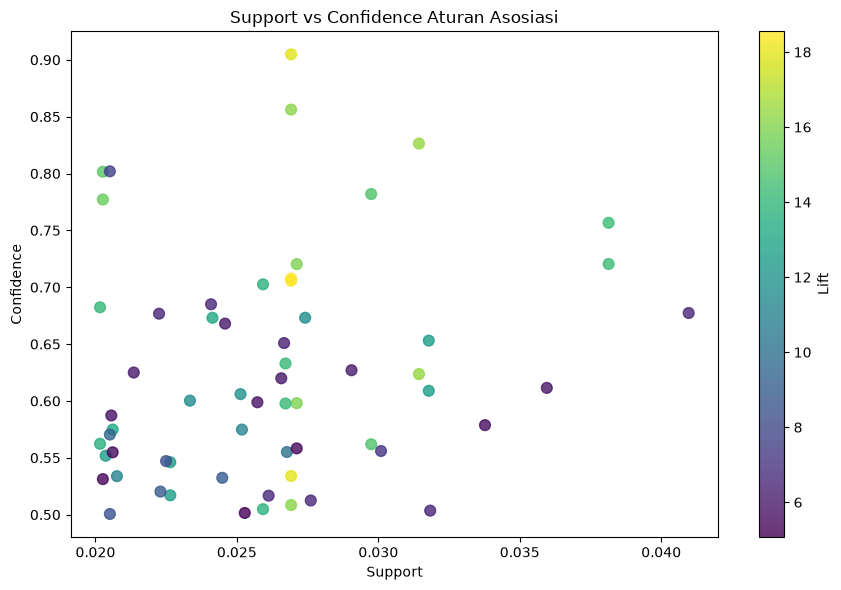

In [20]:
plt.figure(figsize=(9, 6))
sc = plt.scatter(rules_tampil['support'], rules_tampil['confidence'],
                 c=rules_tampil['lift'], cmap='viridis', s=60, alpha=0.8)
plt.colorbar(sc, label='Lift')
plt.title('Support vs Confidence Aturan Asosiasi')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.tight_layout()
plt.show()

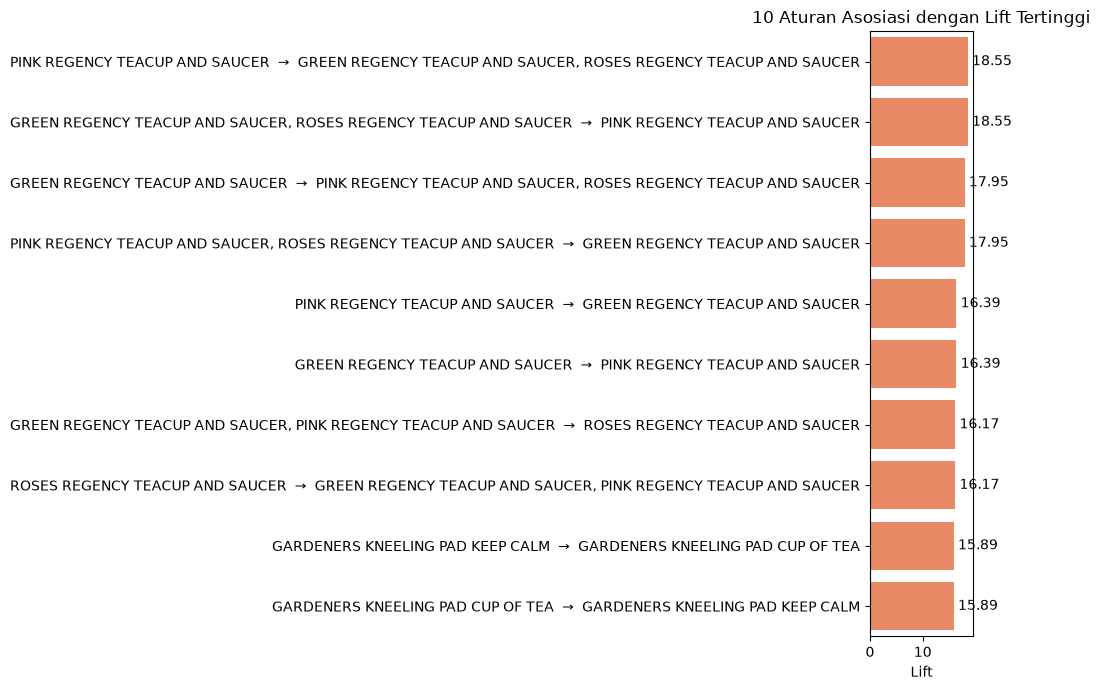

In [21]:
top10 = rules_tampil.head(10).copy()
top10['rule'] = top10['antecedents'] + '  →  ' + top10['consequents']

plt.figure(figsize=(10, 7))
ax = sns.barplot(data=top10, x='lift', y='rule', color='coral')
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)
plt.title('10 Aturan Asosiasi dengan Lift Tertinggi')
plt.xlabel('Lift')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [22]:
# tiga aturan terbaik berdasarkan lift
top3 = rules_tampil.head(3)

display(top3.round(4))

,antecedents,consequents,support,confidence,lift
0,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",0.0269,0.7076,18.5516
1,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",PINK REGENCY TEACUP AND SAUCER,0.0269,0.7057,18.5516
2,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",0.0269,0.5340,17.9506
